# Approximation: die führenden Terme behalten

Fast jede Rechnung in Physik und maschinellem Lernen ist eine Näherung: Man behält die wichtigsten Terme und braucht eine Aussage darüber, wie groß der Rest ist. Das Notebook zeigt die zwei Grundformen, Reihen abschneiden und das Beste aus einer Familie wählen, an sieben Beispielen: den Konvergenzradius einer Taylor-Reihe und die Interpolation nach Tschebyschow, die divergente Stirling-Reihe und die Entropie, die Entfernung von Supernovae aus Pantheon+ als Reihe in der Rotverschiebung, die Post-Newton-Reihe für den Chirp von GW150914, die Trotter-Zerlegung auf einem Quantencomputer mit Gatterrauschen, das Variationsprinzip für Wasserstoff und für einen Variationsschaltkreis, und neuronale Netze außerhalb ihres Trainingsbereichs. Der Code steht in [`code/`](https://github.com/deltorobarba/science/tree/main/code) (`expansions.py` für Taylor, Tschebyschow und Stirling, `cosmography.py` für die Supernovae mit `pantheon.py` als Download, `postnewton.py` für den Chirp, `trotter.py` für die Zeitentwicklung, `variational.py` für Wasserstoff und den Schaltkreis, `extrapolation.py` für die neuronalen Netze); hier stehen nur die Auswahl, die Aufrufe und die Bilder.

**Der rote Faden**

Dies ist das dritte von drei Prinzipien, Kompliziertes einfach zu machen: `principal_axes` behält die wichtigen Richtungen, `symmetries` rechnet Wiederholtes nur einmal, dieses Notebook behält die führenden Terme. Jede Näherung hat zwei Teile: was man behält, und eine Aussage darüber, wie groß der Rest ist. Alle Schritte fragen dasselbe: Wann wird der Rest groß?

- **Schritte 1 und 2, Mathematik:** Wie weit eine Taylor-Reihe trägt, entscheiden Singularitäten in der komplexen Ebene, auch wenn die Funktion auf der reellen Achse glatt ist. Eine Reihe darf sogar divergieren und trotzdem die beste Näherung sein, wenn man rechtzeitig abschneidet.
- **Schritt 3, Kosmologie:** Die Entfernung von Supernovae als Taylor-Reihe in der Rotverschiebung; die Daten reichen über den Konvergenzradius hinaus.
- **Schritt 4, Gravitationswellen:** Die Post-Newton-Reihe in v/c beschreibt den Chirp, solange die Schwarzen Löcher langsam sind. Kurz vor der Verschmelzung sind die Korrekturen nicht mehr klein.
- **Schritt 5, Quantencomputing:** Ein Quantencomputer baut die Zeitentwicklung aus kleinen Schritten (Trotter). Kleinere Schritte senken den Näherungsfehler, aber jedes zusätzliche Gatter rauscht.
- **Schritt 6, Quantenchemie und Quantencomputing:** die zweite Form der Näherung, die beste Funktion aus einer Familie (Variationsprinzip). Ihre Energie liegt immer über der wahren.
- **Schritt 7, Maschinelles Lernen:** Ein neuronales Netz ist auch eine Familie von Funktionen. Im Trainingsbereich passt es; außerhalb entscheidet die Form der Familie, nicht die Menge der Daten.

Die gemeinsame Lehre: Eine Näherung taugt, solange ihr kleiner Parameter klein ist. Wo diese Grenze liegt, sieht man den Daten selten an; sie steckt in der Struktur des Problems, in Singularitäten, in v/c oder in der Form der Familie.

**Einführung: entwickeln und abschneiden, oder das Beste aus einer Familie**

Ein kleines Beispiel zuerst: die Energie eines Teilchens der Masse $m$ mit Impuls $p$ nach der speziellen Relativitätstheorie,

$$E = mc^2\sqrt{1 + x}, \qquad x = (p/mc)^2.$$

Die Taylor-Reihe von $\sqrt{1+x}$ um $x = 0$ ist $1 + x/2 - x^2/8 + x^3/16 - \dots$; eingesetzt ergibt das

$$E = mc^2 + \frac{p^2}{2m} - \frac{p^4}{8m^3c^2} + \dots$$

Der zweite Term ist die kinetische Energie nach Newton: Newtons Mechanik ist die erste Ordnung der Relativitätstheorie. Zum Nachrechnen, mit der kinetischen Energie $E - mc^2$ in Einheiten von $mc^2$:
- Bei $p = 0.1\,mc$ ($x = 0.01$) ist der exakte Wert $\sqrt{1.01} - 1 = 0.0049876$. Newton gibt $0.0050$, also 0.25 % zu viel; mit dem dritten Term kommt $0.0049875$ heraus.
- Bei $p = mc$ ($x = 1$) ist der exakte Wert $\sqrt2 - 1 = 0.4142$. Newton gibt $0.5$, die nächsten Teilsummen springen um den Wert herum ($0.375$, $0.438$, $0.398$) und nähern sich nur langsam.
- Bei $p = 2mc$ ($x = 4$) wird es mit jedem Term schlechter: $2$, $0$, $4$, $-6$ statt $1.236$.

Der Grund steht nicht auf der reellen Achse: $\sqrt{1+x}$ hat bei $x = -1$ einen Verzweigungspunkt, und eine Taylor-Reihe konvergiert nur in einem Kreis bis zur nächsten Singularität, hier für $|x| < 1$. Allgemein gilt (Taylor mit Restglied von Lagrange)

$$f(x) = \sum_{k=0}^{n} \frac{f^{(k)}(0)}{k!}\,x^k + R_n(x), \qquad R_n(x) = \frac{f^{(n+1)}(\xi)}{(n+1)!}\,x^{n+1}$$

für ein $\xi$ zwischen 0 und $x$. Das Restglied sagt, wie groß der Fehler ist. Fourier-Reihen und die Hauptachsen aus `principal_axes` funktionieren genauso: in einer Basis entwickeln und nach wenigen Termen abschneiden. Wie schnell das konvergiert, hängt an der Glattheit der Funktion (Schritt 1).

Die zweite Form der Näherung wählt die beste Funktion aus einer Familie. Beispiel: das Wasserstoffatom mit der Versuchsfunktion $\psi = e^{-\alpha r^2}$ (Hartree-Einheiten). Ihre Energie ist $E(\alpha) = \tfrac32\alpha - 2\sqrt{2\alpha/\pi}$. Die Ableitung verschwindet bei $\alpha = 8/(9\pi) \approx 0.283$, und dort ist $E = -4/(3\pi) \approx -0.424$ Hartree. Die wahre Energie ist $-0.5$: Die Näherung liegt 15 % daneben, aber nie darunter. Für jeden Versuchszustand gilt

$$E[\psi] = \frac{\langle\psi|H|\psi\rangle}{\langle\psi|\psi\rangle} \ge E_0 \qquad \text{(Rayleigh-Ritz)},$$

denn jede Funktion ist eine Mischung aus Eigenzuständen, und jeder davon hat mindestens die Energie $E_0$. Wird die Familie größer, kann die beste Energie nur sinken. So arbeiten die Quantenchemie, Variationsschaltkreise auf Quantencomputern und, mit einer Verlustfunktion statt der Energie, das Training neuronaler Netze.

| Gebiet (Schritt) | kleiner Parameter oder Familie | was die Grenze setzt | Ergebnis im Lauf |
|---|---|---|---|
| Mathematik (1) | Abstand zum Entwicklungspunkt | Pole bei $\pm i$ | Taylor nur für $|x| < 1$; Tschebyschow: Fehler $2.5\cdot10^{-6}$ bei Grad 64, gleichabständig divergent |
| Mathematik (2) | $1/n$ (Stirling) | die Reihe divergiert | bester Abbruch nach etwa $\pi n$ Termen; bei $n = 5$ Fehler $2\cdot10^{-15}$ |
| Kosmologie (3) | Rotverschiebung $z$ | Verzweigungspunkte von $H(z)$ | Radius 1.15; $q_0$ bis $z = 1$ richtig ($-0.49 \pm 0.08$), mit allen Daten verzerrt ($-0.37 \pm 0.05$) |
| Gravitationswellen (4) | $v/c$ | $v/c = 0.41$ an der letzten stabilen Bahn | 16.6 bis 28.6 Zyklen bis zur ISCO, je nach Ordnung |
| Quantencomputing (5) | Zeitschritt $\Delta t$ | Rauschen jedes Gatters | bei $\varepsilon = 10^{-3}$ am besten 8 Schritte, Untreue 0.12 |
| Quantenchemie, Quantencomputing (6) | Gauß-Funktionen, Lagen eines Schaltkreises | Spitze am Kern; Tiefe des Schaltkreises | 8 Gauß-Funktionen: relativ $2\cdot10^{-5}$ zu hoch; Schaltkreis exakt bei $p = 4$ |
| Maschinelles Lernen (7) | neuronales Netz mit 1153 Parametern | Form der Familie außerhalb der Daten | innen auf 2 bis 7 meV genau, außen um Faktoren 2 bis 7 daneben; die richtige Form trifft auf 0.1 eV |

In [1]:
import sys
import urllib.request
from pathlib import Path

CODE = Path.cwd() / "code"
if "google.colab" in sys.modules and not CODE.exists():      # in Colab den Code aus dem Repository holen
    CODE.mkdir()
    for f in ["expansions.py", "pantheon.py", "cosmography.py", "postnewton.py", "trotter.py", "variational.py",
              "extrapolation.py"]:
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/deltorobarba/science/main/code/{f}", CODE / f)
sys.path.insert(0, str(CODE))      # Ordner "code" direkt importieren ("code" ist auch ein Modul der Standardbibliothek)

import expansions, pantheon, cosmography, postnewton, trotter, variational, extrapolation
DATA = Path.cwd() / "data" / "approximation"           # Cache für Pantheon+

**1. Konvergenzradius: Die Grenze liegt in der komplexen Ebene**

Die Funktion $1/(1+x^2)$ ist auf der ganzen reellen Achse glatt und beschränkt. Ihre Taylor-Reihe um 0, $1 - x^2 + x^4 - \dots$, ist die geometrische Reihe in $-x^2$ und konvergiert trotzdem nur für $|x| < 1$: Im Komplexen hat die Funktion Pole bei $x = \pm i$, im Abstand 1 vom Entwicklungspunkt. In der Mitte und rechts wird auf dem Intervall von −5 bis 5 interpoliert, also ein Polynom durch $n + 1$ Punkte der Funktion gelegt, einmal mit gleichen Abständen und einmal mit Tschebyschow-Knoten, die zum Rand hin dichter liegen (`expansions.plot_radius`). Zum Vergleich die Funktion $|x|$ mit einem Knick.

**Begriffe**
- **Konvergenzradius:** der Abstand vom Entwicklungspunkt zur nächsten Singularität in der komplexen Ebene; innerhalb konvergiert die Taylor-Reihe, außerhalb divergiert sie.
- **Runge-Phänomen:** Polynome durch gleichabständige Punkte schwingen am Rand des Intervalls immer stärker, je höher der Grad.
- **Tschebyschow-Knoten:** $x_k = 5\cos\big((2k+1)\pi/(2n+2)\big)$. Mit ihnen fällt der Fehler wie $\rho^{-n}$; $\rho$ folgt aus der Lage der Pole (Bernstein-Ellipse), hier $\rho = (1+\sqrt{26})/5 \approx 1.22$.

Links: Innerhalb von $|x| < 1$ werden die Taylor-Polynome mit jedem Term besser (Grad 32 bei $x = 0.5$: Fehler $5\cdot10^{-11}$), außerhalb schlechter (bei $x = 1.1$: 0.8 mit Grad 4, 12 mit Grad 32). In der Mitte das Runge-Phänomen: Das Polynom 16. Grades durch gleichabständige Punkte schwingt am Rand stark aus, bis −14 bei $x = 4.8$; das durch Tschebyschow-Knoten liegt auf der Kurve. Rechts der größte Fehler: Mit gleichen Abständen wächst er mit dem Grad (14 bei Grad 16, $2\cdot10^6$ bei Grad 48). Mit Tschebyschow-Knoten fällt er genau mit der Rate, die die Pole vorgeben: $2.5\cdot10^{-6}$ bei Grad 64, vorhergesagt $3.0\cdot10^{-6}$. Für $|x|$ mit seinem Knick fällt er nur wie $1/n$ (0.09 bei Grad 32, 0.046 bei Grad 64). Das gilt für jede Entwicklung, auch für Fourier-Reihen und Hauptachsen: Eine analytische Funktion konvergiert geometrisch, eine mit Knick nur wie eine Potenz von $n$. Wie viele Terme man braucht, liest man an den Singularitäten ab, nicht an den Daten.

Taylor-Reihe um 0: 1 − x² + x⁴ − …, Konvergenzradius 1 (Abstand der Pole ±i vom Entwicklungspunkt)
  Grad  4: Fehler bei x = 0.5 1.2e-02, bei x = 0.9 2.9e-01, bei x = 1.1 8.0e-01
  Grad 16: Fehler bei x = 0.5 3.1e-06, bei x = 0.9 8.3e-02, bei x = 1.1 2.5e+00
  Grad 32: Fehler bei x = 0.5 4.7e-11, bei x = 0.9 1.5e-02, bei x = 1.1 1.2e+01
Interpolation auf [−5, 5], größter Fehler (gleichabständig | Tschebyschow | Vorhersage ρ^−n mit ρ = 1.220 | Tschebyschow für |x|):
  Grad  2:   6.5e-01 | 6.0e-01 | 6.7e-01 | 1.1e+00
  Grad  4:   4.4e-01 | 4.0e-01 | 4.5e-01 | 6.2e-01
  Grad  8:   1.0e+00 | 1.7e-01 | 2.0e-01 | 3.3e-01
  Grad 12:   3.7e+00 | 6.9e-02 | 9.2e-02 | 2.3e-01
  Grad 16:   1.4e+01 | 3.3e-02 | 4.2e-02 | 1.8e-01
  Grad 24:   2.6e+02 | 6.9e-03 | 8.5e-03 | 1.2e-01
  Grad 32:   5.1e+03 | 1.4e-03 | 1.7e-03 | 9.1e-02
  Grad 48:   2.2e+06 | 5.9e-05 | 7.2e-05 | 6.1e-02
  Grad 64:         – | 2.5e-06 | 3.0e-06 | 4.6e-02


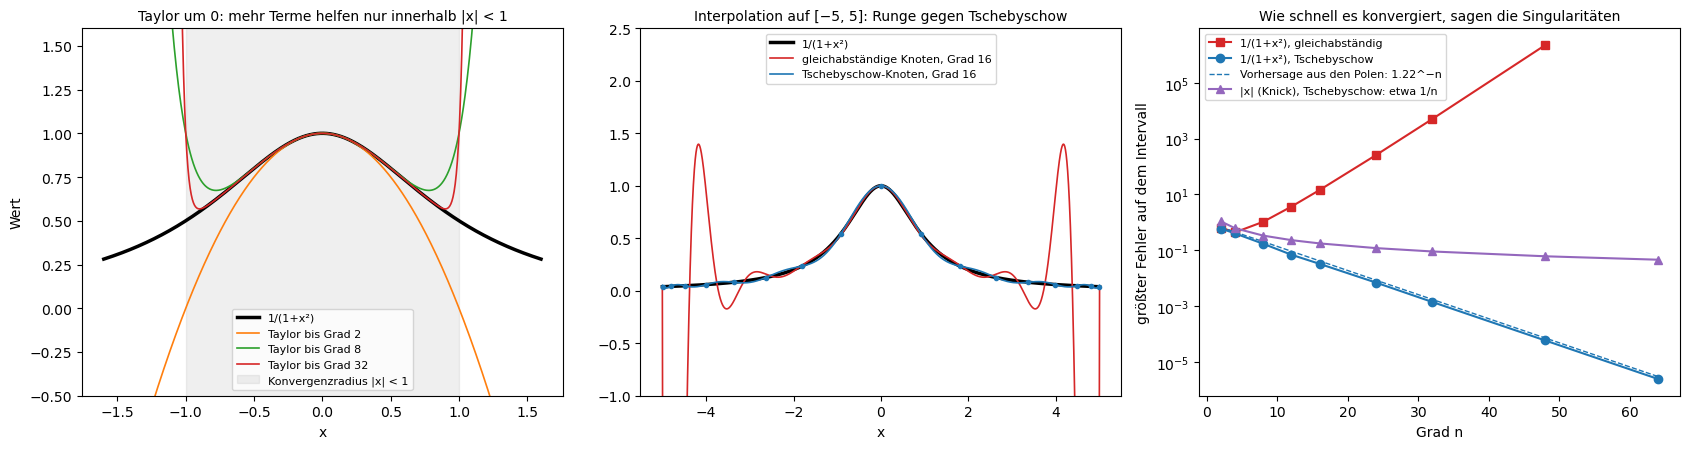

In [2]:
L, DEGREE = 5.0, 16          # Intervall [−L, L] und Grad der gezeigten Interpolation
expansions.plot_radius(L, DEGREE)

**2. Asymptotische Reihen: divergent, aber nützlich**

Die Formel von Stirling nähert $\ln n!$ durch $n\ln n - n + \tfrac12\ln(2\pi n)$ und Korrekturen $\tfrac{1}{12n} - \tfrac{1}{360n^3} + \dots$, deren Koeffizienten aus den Bernoulli-Zahlen stammen. Diese Zahlen wachsen so schnell, dass die Reihe für jedes $n$ divergiert. Trotzdem ist sie nützlich: Die Terme werden erst kleiner und dann größer, und wer beim kleinsten abbricht, hat einen winzigen Fehler. Gerechnet wird mit 50 Stellen für $n$ = 1, 2, 3 und 5 (`expansions.plot_stirling`). Rechts die wichtigste Anwendung: Mit Stirling wird die Zahl der Bitfolgen der Länge $N$ mit $k$ Einsen zu $2^{N H(k/N)}$, mit der Entropie $H$ aus `limits_of_knowledge`.

**Begriffe**
- **Asymptotische Reihe:** Nach $K$ Termen ist der Fehler für großes $n$ klein, aber für festes $n$ wächst er, wenn $K$ gegen unendlich geht. Die Störungsreihen der Quantenelektrodynamik sind von dieser Art (Dyson 1952).
- **Optimaler Abbruch:** beim kleinsten Term aufhören; bei Stirling nach etwa $\pi n$ Termen.
- **Entropie:** $H(p) = -p\log_2 p - (1-p)\log_2(1-p)$, die Information je Zeichen in Bit.

Links: Ohne Korrekturen liegt Stirling bei $n = 1$ um 0.08 daneben. Mit jedem Term wird es zunächst besser, bis zum kleinsten Term nach 3 Korrekturen (Fehler $3\cdot10^{-4}$); danach wächst der Fehler, nach 30 Termen auf $6\cdot10^{30}$. Für größeres $n$ liegt der beste Abbruch später und tiefer: $n = 2$ nach 7 Termen mit $4\cdot10^{-7}$, $n = 3$ nach 10 mit $6\cdot10^{-10}$, $n = 5$ nach 16 mit $2\cdot10^{-15}$, jeweils nahe bei $\pi n$ Termen; der kleinste Fehler fällt grob wie $e^{-2\pi n}$. Eine divergente Reihe ist also keine falsche Formel, sondern eine Näherung mit einem eingebauten Haltepunkt. Rechts nähert sich $\log_2$ der Anzahl der Bitfolgen, geteilt durch $N$, der Entropie; bei $N = 1000$ fehlen nur noch 0.005 Bit je Zeichen, und diese Lücke ist genau der nächste Term von Stirling, $\log_2(2\pi N/4)/(2N)$. Deshalb zählt Shannon mit der Entropie, wie viele Nachrichten es gibt, und Boltzmann, wie viele Mikrozustände ein Gas hat ($S = k\ln W$).

Stirling: ln n! ≈ n ln n − n + ½ ln(2πn) + 1/(12n) − 1/(360n³) + …
  n = 1: ohne Korrektur Fehler 8.1e-02; am besten nach 3 Termen (π·n = 3.1) mit 2.9e-04; nach 30 Termen 6.0e+30
  n = 2: ohne Korrektur Fehler 4.1e-02; am besten nach 7 Termen (π·n = 6.3) mit 3.9e-07; nach 30 Termen 1.0e+13
  n = 3: ohne Korrektur Fehler 2.8e-02; am besten nach 10 Termen (π·n = 9.4) mit 5.9e-10; nach 30 Termen 3.9e+02
  n = 5: ohne Korrektur Fehler 1.7e-02; am besten nach 16 Termen (π·n = 15.7) mit 1.6e-15; nach 30 Termen 2.7e-11
Anzahl der Bitfolgen der Länge N mit k Einsen: (N über k) ≈ 2^(N·H(k/N))
  N =   10: größte Abweichung von H 0.2023 Bit je Zeichen (Stirling: log₂(2πN/4)/(2N) = 0.1987 bei k = N/2)
  N =  100: größte Abweichung von H 0.0365 Bit je Zeichen (Stirling: log₂(2πN/4)/(2N) = 0.0365 bei k = N/2)
  N = 1000: größte Abweichung von H 0.0053 Bit je Zeichen (Stirling: log₂(2πN/4)/(2N) = 0.0053 bei k = N/2)


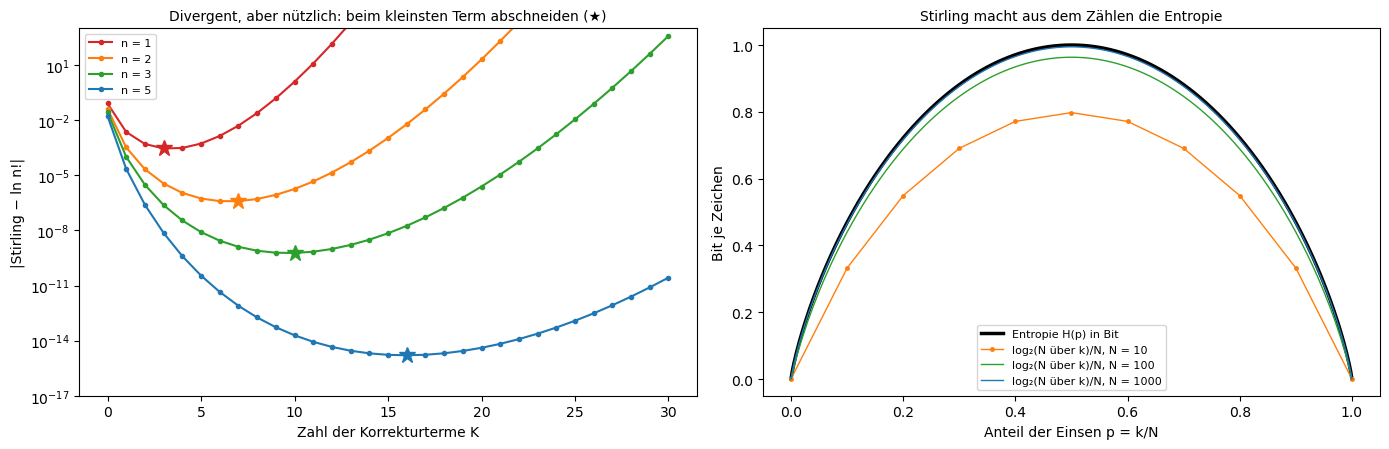

In [3]:
NS = (1, 2, 3, 5)              # n in ln n!
NS_BITS = (10, 100, 1000)      # Länge der Bitfolgen rechts
expansions.plot_stirling(NS, K=30, Ns=NS_BITS)

**3. Kosmographie: die Entfernung von Supernovae als Taylor-Reihe**

Wie weit eine Supernova entfernt ist, hängt von der Expansionsgeschichte des Universums ab. Bei kleiner Rotverschiebung $z$ genügt eine Taylor-Reihe, deren Koeffizienten jede Kosmologie liefert: die Hubble-Konstante $H_0$, die Abbremsung $q_0$ (negativ, wenn die Expansion beschleunigt) und der Ruck $j_0$. Das ist unabhängig vom Modell und deshalb beliebt. Die Daten von Pantheon+ (1590 Supernovae mit $z > 0.01$, volle Kovarianz wie in Schritt 8 von `principal_axes`) reichen aber bis $z = 2.26$. Links werden die Reihen des flachen ΛCDM-Modells mit der exakten Entfernung verglichen, in $z$ und in $y = z/(1+z)$; rechts wird $q_0$ aus der Reihe dritter Ordnung an immer mehr Daten angepasst, mit $q_0$ und $j_0$ als freien Parametern (`cosmography.plot_cosmography`).

**Begriffe**
- **Leuchtkraftentfernung:** $d_L = \frac{c}{H_0}\big[z + \tfrac12(1 - q_0)z^2 - \tfrac16(1 - q_0 - 3q_0^2 + j_0)z^3 + \dots\big]$; im flachen ΛCDM-Modell ist $q_0 = \tfrac32\Omega_m - 1$ und $j_0 = 1$.
- **Verzweigungspunkte:** Dort wird $H(z)$ null; in diesem Modell geschieht das nur bei komplexem $z$, und die nächsten Punkte begrenzen den Konvergenzradius der Reihe in $z$.
- **Variable $y = z/(1+z)$:** bildet $z$ von 0 bis ∞ auf $y$ von 0 bis 1 ab und rückt so alle Daten in den Konvergenzradius (Cattoën und Visser 2007).

Links das flache ΛCDM-Modell mit dem $\Omega_m$, das zu allen Daten passt: 0.332 ± 0.018, wie im Pantheon+-Paper (0.334 ± 0.018). Die Verzweigungspunkte von $E(z)$ liegen bei $z = -0.37 \pm 1.09\,i$, im Abstand 1.15 vom Nullpunkt. Unterhalb davon werden die Reihen in $z$ mit mehr Termen besser (bei $z = 1$ hat Ordnung 24 nur noch $2\cdot10^{-5}$ Fehler), oberhalb schlechter: Bei $z = 2.26$ liegt Ordnung 3 um 33 % daneben, Ordnung 24 um den Faktor 2400. Dort liegen 19 Supernovae. Die Reihe in $y$ konvergiert dagegen im ganzen Bereich (Ordnung 24: $2\cdot10^{-4}$ bei $z = 2.26$), braucht aber mehr Terme: Bei dritter Ordnung ist sie bei $z = 1$ um 20 % daneben, die Reihe in $z$ nur um 4 %. Rechts der Preis in den Daten. Bis $z = 0.3$ ist $q_0$ kaum bestimmt (Fehler 0.24 bis 0.74); bis $z = 0.7$ und 1.0 trifft die Reihe den ΛCDM-Wert $-0.50$ auf 0.1. Mit allen Daten wird sie genauer, aber falsch: $q_0 = -0.37 \pm 0.05$, 2.2 σ neben ΛCDM. Die Reihe in $y$ gibt an allen Daten sogar $q_0 = +0.98$ und $j_0 = -23$, physikalisch unsinnig, weil drei Terme in $y$ nicht reichen. Das ist dasselbe Abwägen wie Bias gegen Varianz im maschinellen Lernen: Mehr Daten senken die Streuung, aber eine zu kleine Familie verzerrt das Ergebnis. Wie weit eine Reihe trägt, sollte man deshalb vor dem Anpassen prüfen.

Pantheon+SH0ES: 1701 Lichtkurven, Kovarianz 1701 × 1701


ΛCDM an alle 1590 Supernovae mit z > 0.01: Ω_m = 0.332 ± 0.018, also q₀ = 3Ω_m/2 − 1 = -0.503 ± 0.027 und j₀ = 1 (χ² = 1403)
Verzweigungspunkte von E(z) bei z = -0.37+1.09j und konjugiert: Konvergenzradius in z 1.15, in y = z/(1+z) 0.91; die Daten reichen bis z = 2.26, also y = 0.69
  Ordnung  3: relativer Fehler bei z = 1 und 2.26: Reihe in z 3.6e-02 und 3.3e-01, Reihe in y 2.0e-01 und 4.5e-01
  Ordnung  8: relativer Fehler bei z = 1 und 2.26: Reihe in z 4.9e-03 und 2.2e+00, Reihe in y 6.7e-03 und 7.7e-02
  Ordnung 24: relativer Fehler bei z = 1 und 2.26: Reihe in z 2.2e-05 und 2.4e+03, Reihe in y 1.1e-07 und 2.4e-04
q₀ aus der Reihe dritter Ordnung (q₀ und j₀ frei) gegen die größte Rotverschiebung der Auswahl:
  z < 0.15:  715 Supernovae, q₀ = -0.05 ± 0.74, j₀ = -7.0 ± 13.1, Abstand zu ΛCDM +0.6 σ
  z < 0.20:  837 Supernovae, q₀ = +0.11 ± 0.47, j₀ = -6.8 ± 5.7, Abstand zu ΛCDM +1.3 σ


  z < 0.30: 1096 Supernovae, q₀ = -0.26 ± 0.24, j₀ = -1.2 ± 2.5, Abstand zu ΛCDM +1.0 σ


  z < 0.50: 1380 Supernovae, q₀ = -0.41 ± 0.13, j₀ = +0.1 ± 1.1, Abstand zu ΛCDM +0.6 σ


  z < 0.70: 1515 Supernovae, q₀ = -0.50 ± 0.09, j₀ = +1.0 ± 0.6, Abstand zu ΛCDM +0.0 σ


  z < 1.00: 1565 Supernovae, q₀ = -0.49 ± 0.08, j₀ = +0.9 ± 0.5, Abstand zu ΛCDM +0.1 σ


  z < 1.50: 1583 Supernovae, q₀ = -0.38 ± 0.07, j₀ = +0.0 ± 0.3, Abstand zu ΛCDM +1.8 σ


  z < 2.30: 1590 Supernovae, q₀ = -0.37 ± 0.05, j₀ = -0.0 ± 0.2, Abstand zu ΛCDM +2.2 σ


  dieselbe Reihe in y an alle Daten: q₀ = +0.98 ± 0.17, j₀ = -23.4 ± 1.1


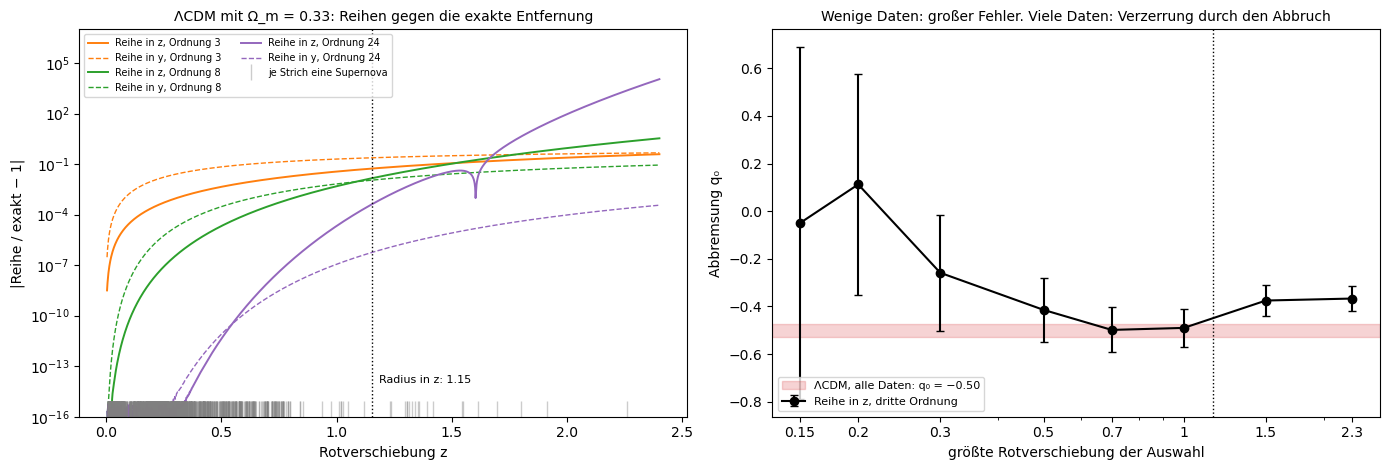

In [4]:
sn, sn_cov = pantheon.load(DATA / "pantheon")       # 2 Dateien, zusammen 34 MB, beim ersten Lauf von GitHub
ZMAX = (0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.3)     # größte Rotverschiebung der Auswahl
omega_m, q0_fits = cosmography.plot_cosmography(sn, sn_cov, ZMAX)

**4. Post-Newton: der Chirp von GW150914 als Reihe in v/c**

Zwei Schwarze Löcher, die sich umkreisen, strahlen Gravitationswellen ab, verlieren Energie und kommen sich näher; die Frequenz der Welle steigt (Chirp). In Schritt 4 von `principal_axes` passte die Newtonsche Formel zu den Daten von GW150914. Sie ist die nullte Ordnung einer Reihe in $x = (v/c)^2$, der Post-Newton-Reihe; die Korrekturen sind bis zur Ordnung $(v/c)^7$ bekannt (3.5PN), darunter bei 1.5PN der Teil der Welle, der an der Krümmung der Raumzeit zurückgestreut wird („tail“). Gerechnet wird mit den Massen von GW150914 von 20 Hz bis zur letzten stabilen Kreisbahn, mit $dx/dt = \frac{64\eta}{5M}x^5\,[1 + a_1x + a_{1.5}x^{3/2} + \dots]$ und den Koeffizienten aus Blanchet (2014) (`postnewton.plot_chirp_orders`). Zum Vergleich zwei Neutronensterne ab 10 Hz.

**Begriffe**
- **Ordnung nPN:** eine Korrektur relativ zu Newton mit dem Faktor $(v/c)^{2n}$; 1PN ist $(v/c)^2$, 3.5PN ist $(v/c)^7$.
- **Letzte stabile Kreisbahn (ISCO):** im Abstand $6GM/c^2$; weiter innen stürzen die Körper ineinander. Dort ist $v/c = 1/\sqrt6 \approx 0.41$.
- **Zyklen:** die Zahl der Wellenberge bis zur ISCO. Ein Suchfilter (matched filter) muss die Phase auf einen Bruchteil eines Zyklus treffen, sonst passt er nicht mehr zum Signal.

Links: Bei 20 Hz ist $v/c = 0.28$, an der letzten stabilen Bahn bei 62 Hz schon 0.41. Wegen der großen Masse liegt diese Bahn so tief; die Verschmelzung und das Ausschwingen bis etwa 250 Hz beschreibt die Reihe gar nicht mehr. Die Korrekturen sind dort nicht klein: 1PN −0.48, der Tail-Term bei 1.5PN +0.86, 3PN +0.52, mit wechselnden Vorzeichen. Rechts: Newton gibt 19.8 Zyklen bis zur ISCO, 1PN 28.6, 1.5PN 17.6, dann 17.0, 19.2, 16.9 und 16.6. Die Reihe springt also um mehrere Zyklen und kommt erst bei den höchsten Ordnungen zur Ruhe (zuletzt −0.3). Ein Suchfilter, der auch nur einen Zyklus falsch zählt, passt nicht mehr zum Signal. Für schwere Schwarze Löcher nutzt LIGO deshalb Modelle, die die Reihe mit numerischer Relativitätstheorie ergänzen (EOB, IMRPhenom). Bei zwei Neutronensternen ab 10 Hz sind die Korrekturen relativ klein (1PN ändert 3 % statt 45 %), aber es sind rund 16 000 Zyklen: Die Ordnungen ändern die Zahl um +461, −227, −8, +13, −8 und zuletzt noch −0.7 Zyklen. Dort braucht man jede bekannte Ordnung, weil sich kleine Fehler über viele Umläufe aufsummieren.

GW150914 mit 39 und 32 Sonnenmassen: Chirp-Masse 30.7, η = 0.2476; von 20 Hz (v/c = 0.28) bis zur letzten stabilen Bahn bei 62 Hz (v/c = 0.41)
  bis   0PN: 0.692 s und  19.8 Zyklen bis 62 Hz
  bis   1PN: 0.975 s und  28.6 Zyklen bis 62 Hz, Änderung +8.8
  bis 1.5PN: 0.626 s und  17.6 Zyklen bis 62 Hz, Änderung -11.0
  bis   2PN: 0.606 s und  17.0 Zyklen bis 62 Hz, Änderung -0.6
  bis 2.5PN: 0.677 s und  19.2 Zyklen bis 62 Hz, Änderung +2.3
  bis   3PN: 0.607 s und  16.9 Zyklen bis 62 Hz, Änderung -2.3
  bis 3.5PN: 0.598 s und  16.6 Zyklen bis 62 Hz, Änderung -0.3
Zum Vergleich zwei Neutronensterne mit 1.4 und 1.4 Sonnenmassen ab 10 Hz: 0PN 16 031, 1PN 16 492, 1.5PN 16 265, 2PN 16 257, 2.5PN 16 269, 3PN 16 262, 3.5PN 16 261 Zyklen; der letzte Schritt ändert -0.7


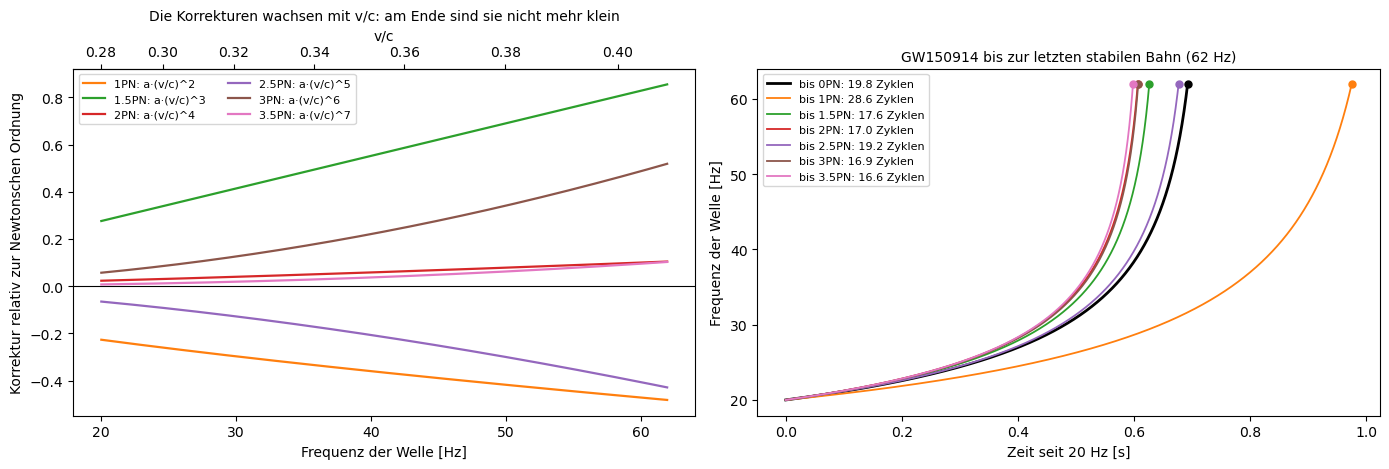

In [5]:
M1, M2 = 39, 32            # Massen von GW150914, wie sie im Detektor erscheinen (rotverschoben) [Sonnenmassen]
F_START = 20               # Frequenz, ab der LIGO die Welle sieht [Hz]
runs = postnewton.plot_chirp_orders(M1, M2, F_START)

**5. Trotter: Zeitentwicklung in kleinen Schritten**

Ein Quantencomputer soll die Zeitentwicklung $e^{-iHt}$ einer Ising-Kette ausführen, $H = A + B$ mit der Kopplung $A = -\sum_i Z_iZ_{i+1}$ und dem Querfeld $B = -\sum_i X_i$. Er kann $e^{-iA\Delta t}$ und $e^{-iB\Delta t}$ einzeln als Gatter bauen, aber nicht $e^{-iHt}$, weil $A$ und $B$ nicht vertauschen. Die Trotter-Formel wechselt deshalb in kleinen Schritten zwischen beiden ab. Ihr Fehler ist der Rest einer Taylor-Entwicklung in $\Delta t$, mit dem Kommutator $[A, B]$ als Koeffizient; die symmetrische Version (Strang) hebt den Term erster Ordnung auf. Gerechnet wird exakt mit 8 Spins, ohne Hardware: links die Korrelation benachbarter Spins nach dem Einschalten der Kopplung, rechts die Untreue des Zustands bei $t = 2$ gegen die Zahl der Schritte, auch mit einem einfachen Rauschmodell, in dem jedes CNOT-Gatter nur mit Wahrscheinlichkeit $1 - \varepsilon$ gelingt (`trotter.plot_trotter`).

**Begriffe**
- **Trotter erster Ordnung:** $(e^{-iB\Delta t}e^{-iA\Delta t})^n$; der Fehler im Zustand wächst wie $\Delta t$.
- **Zweite Ordnung:** $(e^{-iB\Delta t/2}e^{-iA\Delta t}e^{-iB\Delta t/2})^n$; Fehler wie $\Delta t^2$, bei gleich vielen CNOT-Gattern, denn die Halbschritte mit $B$ sind Gatter auf einzelnen Qubits.
- **Untreue:** $1 - |\langle\psi_\text{exakt}|\psi\rangle|^2$, etwa das Quadrat des Abstands der Zustände; deshalb fällt sie wie $1/\text{Schritte}^2$ und $1/\text{Schritte}^4$.
- **ε:** Fehler je CNOT-Gatter; heutige supraleitende Hardware liegt bei einigen $10^{-3}$. Ein Schritt kostet hier $2 \cdot 7 = 14$ CNOT-Gatter.

Links: Mit $\Delta t = 0.25$ folgt die zweite Ordnung der exakten Kurve bis auf 0.06, die erste weicht bis 0.15 ab, bei gleich vielen CNOT-Gattern. Rechts gestrichelt der reine Näherungsfehler bei $t = 2$: Er fällt in erster Ordnung wie $1/\text{Schritte}^2$ (Untreue $5\cdot10^{-4}$ nach 128 Schritten), in zweiter wie $1/\text{Schritte}^4$ ($2\cdot10^{-7}$). Die Schranke aus dem Kommutator wäre für den Abstand der Zustände etwa achtmal zu pessimistisch (0.30 gegen 0.037 nach 128 Schritten); wie man die Schranke schärfer macht, wird noch erforscht. Mit Rauschen ändert sich das Bild: Bei $\varepsilon = 10^{-3}$ verdirbt jedes Gatter den Zustand ein wenig, und am besten sind 8 Schritte (112 CNOT-Gatter) mit einer Untreue von 0.12 in zweiter und 0.19 in erster Ordnung; mehr Schritte machen es schlechter. Erst bei $\varepsilon = 10^{-4}$ lohnen 16 Schritte (Untreue 0.023). Auf echter Hardware zählt deshalb die Ordnung der Formel mehr als die Zahl der Schritte: Sie erreicht dieselbe Genauigkeit mit weniger Gattern.

Ising-Kette mit 8 Spins, J = h = 1, Start |+…+⟩; ‖[A, B]‖ = 19.0; je Trotter-Schritt 14 CNOT-Gatter


Bei t = 2: Abstand ‖ψ_Trotter − ψ_exakt‖ (Schranke erster Ordnung t²‖[A,B]‖/(2·Schritte)):
    1 Schritte (  14 CNOT): erste Ordnung 1.3e+00 (Schranke 3.8e+01), zweite Ordnung 1.5e+00
    2 Schritte (  28 CNOT): erste Ordnung 1.4e+00 (Schranke 1.9e+01), zweite Ordnung 1.4e+00
    4 Schritte (  56 CNOT): erste Ordnung 1.5e+00 (Schranke 9.5e+00), zweite Ordnung 8.6e-01
    8 Schritte ( 112 CNOT): erste Ordnung 7.0e-01 (Schranke 4.8e+00), zweite Ordnung 2.1e-01
   16 Schritte ( 224 CNOT): erste Ordnung 3.2e-01 (Schranke 2.4e+00), zweite Ordnung 5.2e-02
   32 Schritte ( 448 CNOT): erste Ordnung 1.5e-01 (Schranke 1.2e+00), zweite Ordnung 1.3e-02
   64 Schritte ( 896 CNOT): erste Ordnung 7.4e-02 (Schranke 5.9e-01), zweite Ordnung 3.2e-03
  128 Schritte (1792 CNOT): erste Ordnung 3.7e-02 (Schranke 3.0e-01), zweite Ordnung 8.1e-04
  mit Rauschen ε = 0.001 je CNOT, erste Ordnung: am besten 8 Schritte, Untreue 0.191
  mit Rauschen ε = 0.001 je CNOT, zweite Ordnung: am besten 8 Schritte, Untreue 

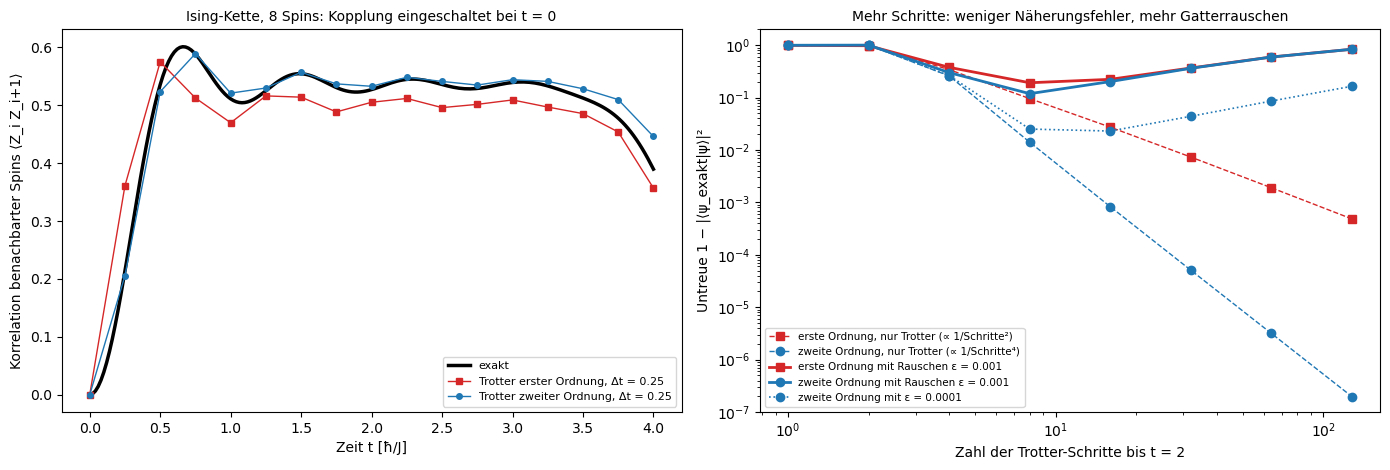

In [6]:
SPINS, TIME = 8, 2.0           # Länge der Kette, Zeit für den rechten Plot [ħ/J]
DT_SHOW = 0.25                 # Schrittweite im linken Plot
NOISE = (1e-3, 1e-4)           # Fehler je CNOT-Gatter
trotter.plot_trotter(SPINS, TIME, DT_SHOW, eps=NOISE)

**6. Variationsprinzip: das Beste aus einer Familie**

Links das Wasserstoffatom aus der Einführung, jetzt mit $K$ Gauß-Funktionen statt einer. Ihre Exponenten werden optimiert, die Koeffizienten folgen aus einem verallgemeinerten Eigenwertproblem. So rechnet die Quantenchemie, denn mit Gauß-Funktionen lassen sich die Integrale in Molekülen schnell ausrechnen. Rechts dasselbe Prinzip auf einem Quantencomputer: Ein Schaltkreis aus $p$ Lagen, jede mit einem Winkel für die Kopplung und einem für das Feld, soll den Grundzustand eines Rings aus 8 Spins herstellen; die Winkel werden klassisch optimiert wie bei einem VQE (`variational.plot_variational`, simuliert).

**Begriffe**
- **Rayleigh-Ritz:** Die kleinste Energie in einer Familie ist eine obere Schranke für $E_0$; eine größere Familie kann sie nur senken.
- **Spitze am Kern (Kato-Cusp):** Die wahre Wellenfunktion $e^{-r}$ hat bei $r = 0$ einen Knick, jede Gauß-Funktion ist dort flach. Wie der Knick von $|x|$ in Schritt 1 bremst er die Konvergenz.
- **Hamiltonscher Variationsansatz:** $p$ Lagen $e^{-i\gamma_k H_{ZZ}}e^{-i\beta_k H_X}$ auf dem Zustand $|{+}\dots{+}\rangle$, mit $H$ wie in Schritt 5, aber auf einem Ring und im kritischen Feld $h = 1$. Der Ansatz respektiert die Symmetrien des Rings (Schritt 2 von `symmetries`).

Links: Eine Gauß-Funktion (E = −0.4244) ist am Kern viel zu flach und außen zu breit. Mit zwei und vier nähert sich die Kurve der wahren, nur die Spitze bei $r = 0$ bleibt rund. Rechts liegen alle Energien über $E_0$, wie Rayleigh-Ritz es verlangt. Für Wasserstoff fällt der Fehler mit jeder Gauß-Funktion, aber langsamer als exponentiell: von $7.6\cdot10^{-2}$ Hartree bei einer über $7\cdot10^{-4}$ bei vier auf $9\cdot10^{-6}$ bei acht. Den Knick am Kern treffen glatte Funktionen nie. Der Schaltkreis für den Ising-Ring braucht dagegen nur vier Lagen (acht Winkel): Bei $p = 1$ bis 3 liegt er 6 %, 3 % und 2 % über $E_0$, bei $p = 4 = n/2$ trifft er den Grundzustand bis auf Rundungsfehler ($10^{-14}$, Überlapp 1.000000), wie Ho und Hsieh (2019) gezeigt haben. Eine Familie mit der richtigen Struktur kann also exakt werden, eine bequeme Familie wie die Gauß-Funktionen nur immer besser. Bei größeren Systemen kommt ein Problem hinzu, das hier nicht auftritt: Die Optimierung kann in flachen Landschaften steckenbleiben (Barren Plateaus).

Wasserstoff, exakt −0.5 Hartree; K Gauß-Funktionen mit optimierten Exponenten:
  K = 1: E = -0.424413 Hartree, Fehler 7.6e-02 (α = 0.2829; analytisch 8/(9π) = 0.2829 und E = −4/(3π) = -0.424413)
  K = 2: E = -0.485813 Hartree, Fehler 1.4e-02
  K = 3: E = -0.496979 Hartree, Fehler 3.0e-03
  K = 4: E = -0.499278 Hartree, Fehler 7.2e-04
  K = 5: E = -0.499810 Hartree, Fehler 1.9e-04


  K = 6: E = -0.499946 Hartree, Fehler 5.4e-05
  K = 7: E = -0.499983 Hartree, Fehler 1.7e-05


  K = 8: E = -0.499991 Hartree, Fehler 9.3e-06
Ising-Ring mit 8 Spins bei h = 1: E₀ = -10.251662; Variationsschaltkreis mit p Lagen (2p Winkel):
  p = 1: E = -9.656854, Fehler 5.9e-01, Überlapp mit dem Grundzustand 0.703702


  p = 2: E = -9.952135, Fehler 3.0e-01, Überlapp mit dem Grundzustand 0.823070


  p = 3: E = -10.054679, Fehler 2.0e-01, Überlapp mit dem Grundzustand 0.895043


  p = 4: E = -10.251662, Fehler 1.1e-14, Überlapp mit dem Grundzustand 1.000000


  p = 5: E = -10.251662, Fehler 1.5e-13, Überlapp mit dem Grundzustand 1.000000


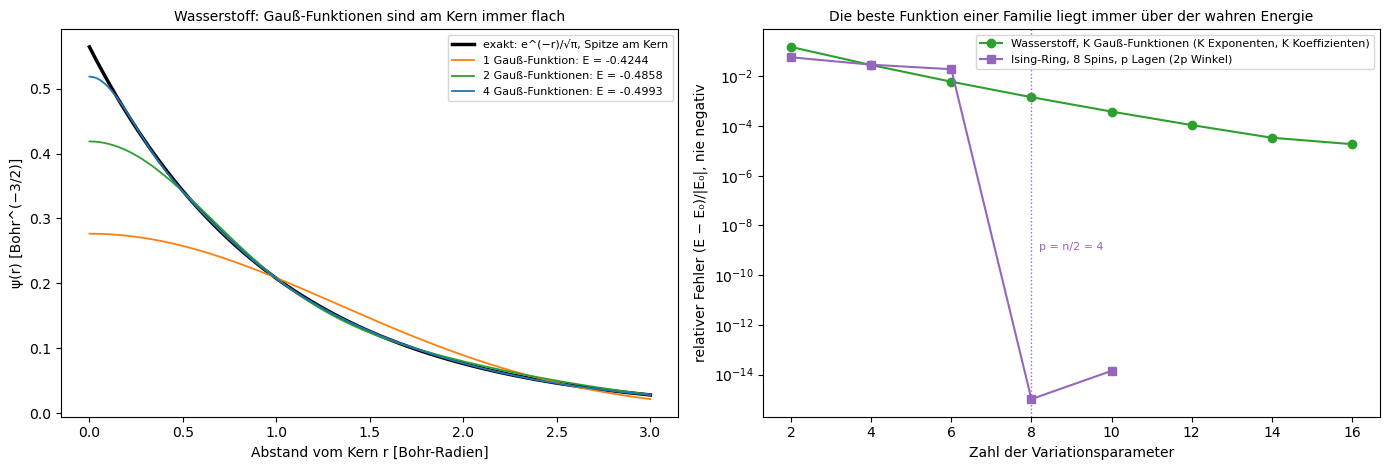

In [7]:
GAUSSIANS = range(1, 9)        # Zahl der Gauß-Funktionen für Wasserstoff
SPINS, LAYERS = 8, range(1, 6) # Ring aus 8 Spins, Lagen des Schaltkreises
variational.plot_variational(GAUSSIANS, SPINS, LAYERS)

**7. Neuronale Netze: innen nähern, außen raten**

Ein neuronales Netz kann jede stetige Funktion auf einem beschränkten Bereich beliebig gut nähern (Universal Approximation Theorem); über das Verhalten außerhalb sagt der Satz nichts. Das Beispiel kommt aus der Molekulardynamik, wo gelernte Potentiale heute Materialien und Proteine simulieren: die Energie des H₂-Moleküls gegen den Abstand der Kerne, hier als Morse-Potential mit den Konstanten von H₂. Gelernt wird aus 60 verrauschten Punkten zwischen 0.6 und 1.0 Å, Energien bis 0.74 eV über dem Minimum; das ist etwa der Bereich, den das schwingende Molekül bei normalen Temperaturen einnimmt (die Nullpunktsenergie ist 0.27 eV). Verglichen werden die harmonische Näherung (Taylor bis zur zweiten Ordnung), ein Polynom sechsten Grades, je fünf Netze mit tanh und mit ReLU (zwei Schichten mit je 32 Neuronen) und eine Familie mit der richtigen Form, das Morse-Potential mit drei freien Parametern (`extrapolation.train`, `extrapolation.plot_extrapolation`).

**Begriffe**
- **tanh und ReLU:** Aktivierungsfunktionen der Neuronen; tanh wird für große Eingaben konstant, ReLU ($\max(0, x)$) wird linear. Genau so verhält sich das ganze Netz außerhalb der Daten.
- **Ensemble:** fünf gleich gebaute Netze mit verschiedenen Startwerten. Wo sie auseinanderlaufen, rät das Netz; ihre Streuung ist ein einfaches Maß für die Unsicherheit.
- **Dissoziation:** Bei großem Abstand zerfällt das Molekül in zwei Atome, die Energie geht gegen $D_e = 4.75$ eV.

Links: Im grauen Trainingsbereich liegen alle Modelle auf der Kurve, das Polynom und die Netze bis auf 2 bis 7 meV, die Parabel bis auf 83 meV, weil schon dort die Anharmonizität stört. Außerhalb trennen sie sich nach ihrer Form: Die Parabel steigt endlos (147 eV bei 4 Å statt 4.73), das Polynom stürzt bei 1.3 Å ab, die Netze mit tanh werden flach und sagen bei 4 Å 0.7 bis 1.4 eV voraus, die mit ReLU werden linear und sagen 10 bis 12.5 eV voraus. Keines findet die Dissoziation, und bei 0.4 Å liegen alle Netze bei 1.2 bis 2.0 eV statt 4.2. Die fünf Netze jeder Art stimmen innen überein und laufen außen auseinander; ihre Streuung zeigt, wo sie raten. Nur die Familie mit der richtigen Form extrapoliert: drei Parameter, aus denselben Daten $D_e = 4.82$ eV statt 4.75 und $V(4\,\text{Å})$ auf 0.1 eV genau. Rechts derselbe Befund als Fehler. Das ist die Lehre für jedes gelernte Modell: vor dem Einsatz außerhalb des Trainingsbereichs prüfen, und Wissen über Asymptotik, Symmetrien oder Erhaltungssätze in die Familie einbauen, statt mehr Daten aus demselben Bereich zu sammeln.

Training: 60 Punkte zwischen 0.6 und 1.0 Å (Energie 0.48 bis 0.74 eV über dem Minimum), Rauschen 2 meV; Morse-Form angepasst: D = 4.82 eV, a = 1.93/Å, r₀ = 0.7416 Å (wahr 4.747, 1.94, 0.7414)
Wahr: V(0.4 Å) = 4.21 eV, V(2 Å) = 3.96 eV, V(4 Å) = 4.73 eV
  Parabel (harmonisch)       Fehler im Training höchstens  83.2 meV; V(0.4 Å) 1.9, V(2 Å) 21.6, V(4 Å) 147.3 eV
  Polynom, Grad 6            Fehler im Training höchstens   2.4 meV; V(0.4 Å) 3.3, V(2 Å) -685.3, V(4 Å) -3e+05 eV
  5 Netze mit tanh           Fehler im Training höchstens   3.2 meV; V(0.4 Å) 1.2 bis 1.5, V(2 Å) 0.8 bis 1.5, V(4 Å) 0.7 bis 1.4 eV
  5 Netze mit relu           Fehler im Training höchstens   6.5 meV; V(0.4 Å) 1.5 bis 2.0, V(2 Å) 4.0 bis 4.8, V(4 Å) 9.9 bis 12.5 eV
  Morse-Form (3 Parameter)   Fehler im Training höchstens   1.2 meV; V(0.4 Å) 4.2, V(2 Å) 4.0, V(4 Å) 4.8 eV


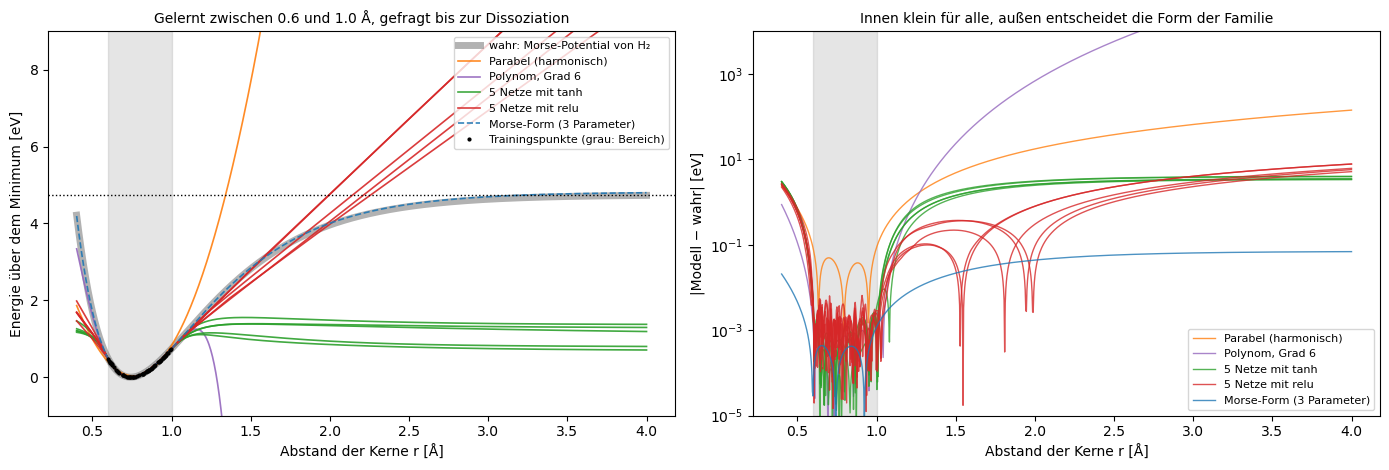

In [8]:
TRAIN = (0.6, 1.0)             # Trainingsbereich [Å]
r_train, v_train, models = extrapolation.train(*TRAIN)
extrapolation.plot_extrapolation(r_train, v_train, models, *TRAIN)

**8. Ausblick: Variationsinferenz**

Das Variationsprinzip aus Schritt 6 hat ein Gegenstück in Statistik und maschinellem Lernen. Oft will man eine Verteilung $p(z \mid x)$ kennen, die zu kompliziert ist, etwa die Verteilung verborgener Variablen $z$ eines Modells bei gegebenen Daten $x$. Dann wählt man die beste Verteilung $q(z)$ aus einer einfachen Familie, zum Beispiel aus Gauß-Verteilungen. Für jedes $q$ gilt $\log p(x) \ge \mathbb{E}_q[\log p(x, z)] - \mathbb{E}_q[\log q(z)] = \text{ELBO}$, und die Lücke ist genau der Abstand $\mathrm{KL}(q\,\|\,p(z \mid x))$ zwischen $q$ und der wahren Verteilung. Mit $-\log p(x, z)$ als Energie ist das dieselbe Aussage wie in Schritt 6: Die freie Energie einer Versuchsverteilung, $-\text{ELBO}$, liegt immer über der wahren, $-\log p(x)$. In der statistischen Physik heißt das die Ungleichung von Gibbs und Bogoliubov, im maschinellen Lernen ist es die Verlustfunktion jedes Variational Autoencoders.

Ein nächster Schritt mit Code wäre eine Mischung aus zwei Gauß-Verteilungen, angenähert durch eine einzige: Man sähe, dass $q$ sich auf eine der beiden Spitzen legt, statt beide abzudecken, weil $\mathrm{KL}(q\,\|\,p)$ jede Wahrscheinlichkeit von $q$ dort bestraft, wo $p$ klein ist.